In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn flask joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import joblib

In [3]:
df = pd.read_csv(r"C:\Users\surbh\Downloads\archive (2).zip")

df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [4]:
df.shape

(200, 5)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [6]:
df.describe()

,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [7]:
df.shape

(200, 5)

In [8]:
df.isnull().sum()

Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

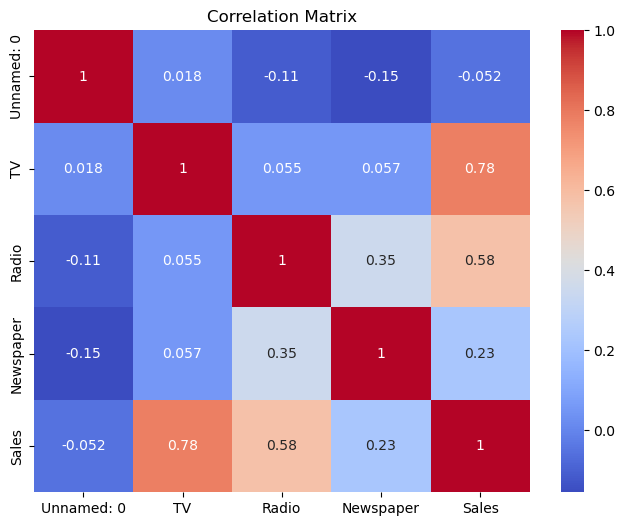

In [10]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

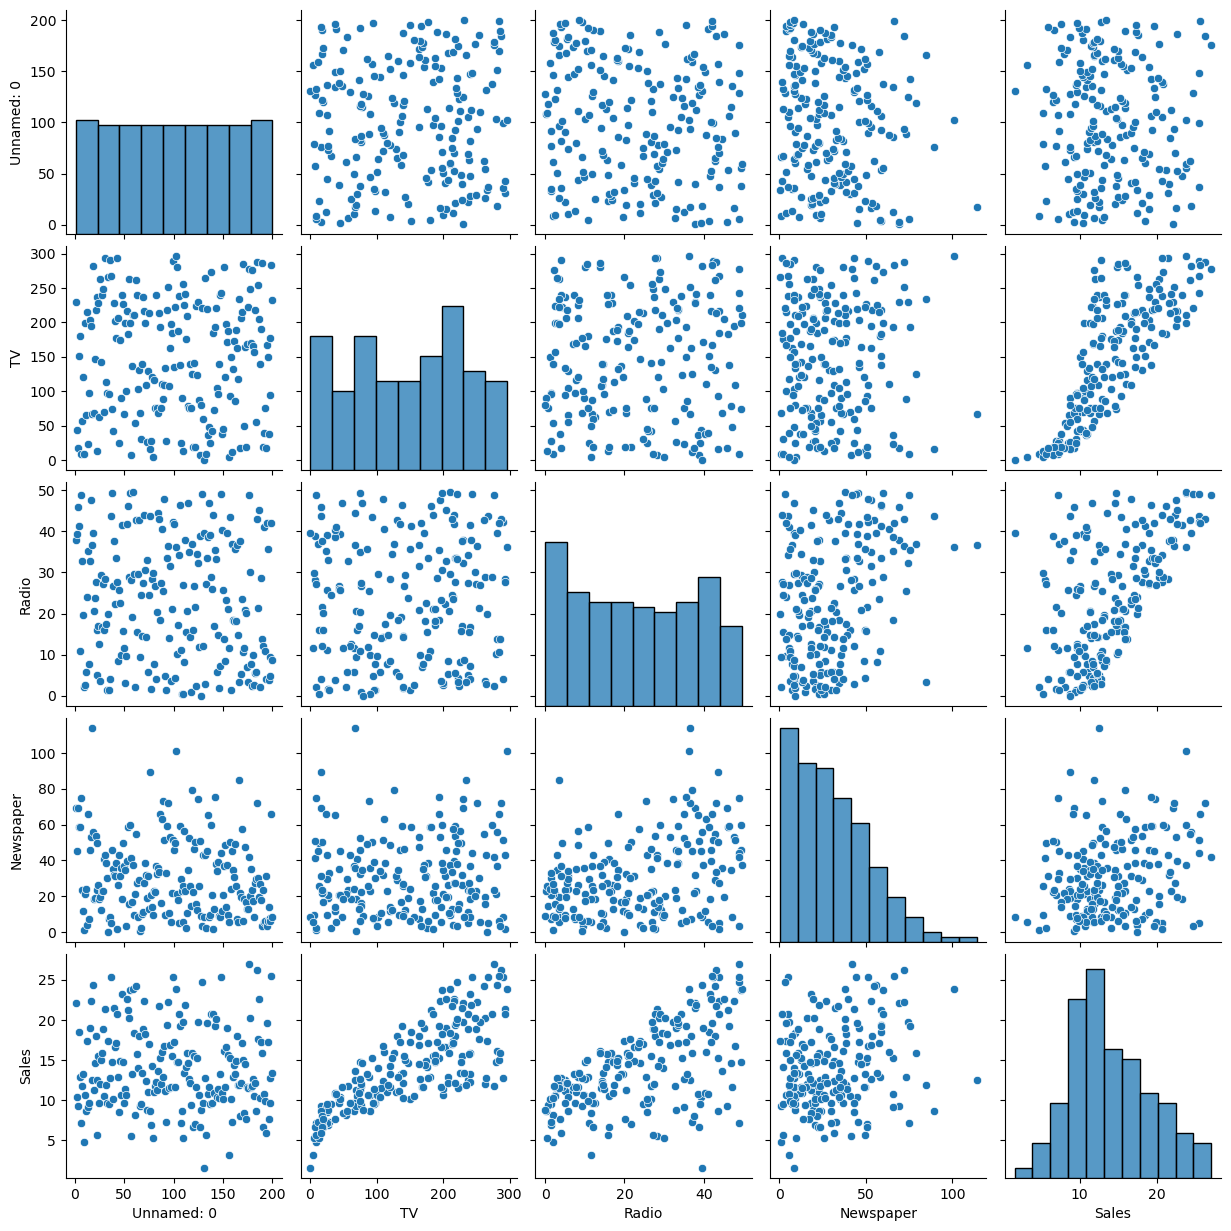

In [11]:
sns.pairplot(df)
plt.show()

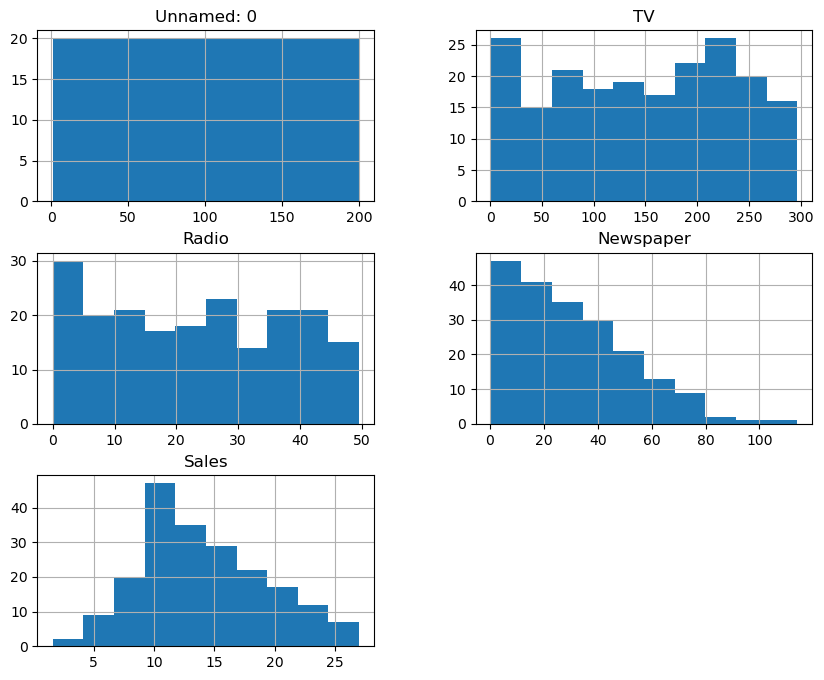

In [12]:
df.hist(figsize=(10,8))
plt.show()

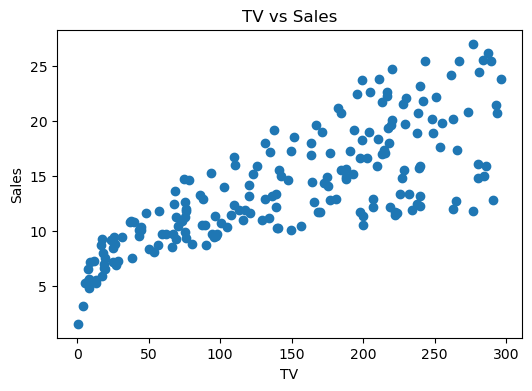

In [13]:
plt.figure(figsize=(6,4))
plt.scatter(df["TV"], df["Sales"])
plt.xlabel("TV")
plt.ylabel("Sales")
plt.title("TV vs Sales")
plt.show()

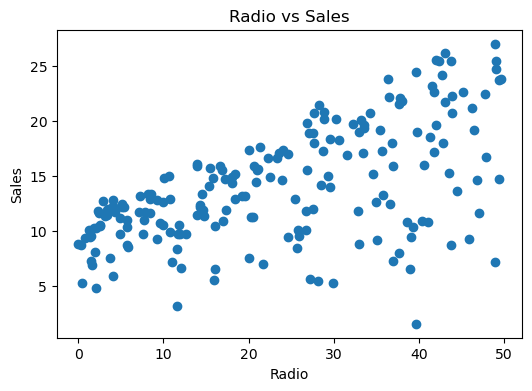

In [14]:
plt.figure(figsize=(6,4))
plt.scatter(df["Radio"], df["Sales"])
plt.xlabel("Radio")
plt.ylabel("Sales")
plt.title("Radio vs Sales")
plt.show()

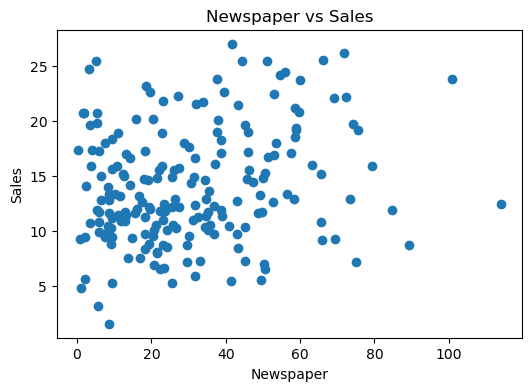

In [15]:
plt.figure(figsize=(6,4))
plt.scatter(df["Newspaper"], df["Sales"])
plt.xlabel("Newspaper")
plt.ylabel("Sales")
plt.title("Newspaper vs Sales")
plt.show()

In [16]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [18]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [19]:
y_pred = model.predict(X_test)

In [20]:
print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE : 1.4607567168117606
MSE : 3.1740973539761046
RMSE: 1.7815996615334502
R2 Score: 0.899438024100912


In [21]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

comparison.head(10)

,Actual,Predicted
95,16.9,16.408024
15,22.4,20.889882
30,21.4,21.553843
158,7.3,10.608503
128,24.7,22.112373
115,12.6,13.105592
69,22.3,21.057192
170,8.4,7.461010
174,11.5,13.606346
45,14.9,15.155070


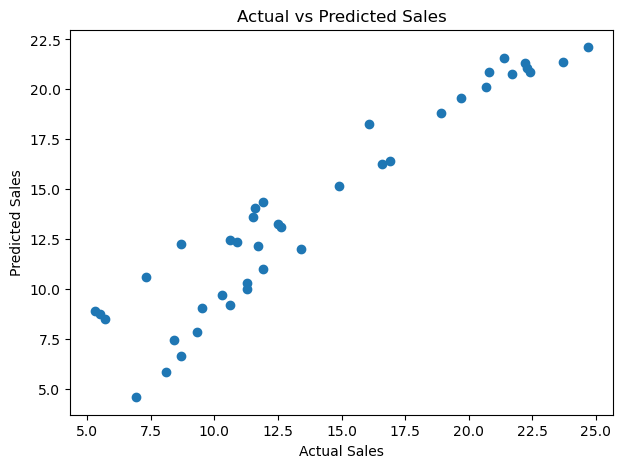

In [22]:
plt.figure(figsize=(7,5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.show()

In [23]:
tv = 200
radio = 40
newspaper = 30

prediction = model.predict([[tv, radio, newspaper]])

print("Predicted Sales:", prediction[0])

Predicted Sales: 19.575606431481972


C:\Users\surbh\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [24]:
print("Intercept:", model.intercept_)

coef = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coef

Intercept: 2.9790673381226274


,Feature,Coefficient
0,TV,0.044730
1,Radio,0.189195
2,Newspaper,0.002761


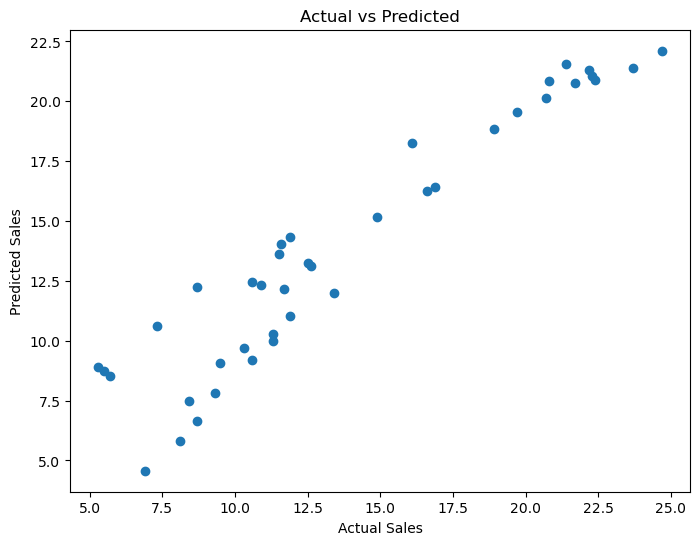

In [25]:
plt.figure(figsize=(8,6))

plt.scatter(y_test,y_pred)

plt.xlabel("Actual Sales")

plt.ylabel("Predicted Sales")

plt.title("Actual vs Predicted")

plt.show()

In [26]:
df.head(10)

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9
5,6,8.7,48.9,75.0,7.2
6,7,57.5,32.8,23.5,11.8
7,8,120.2,19.6,11.6,13.2
8,9,8.6,2.1,1.0,4.8
9,10,199.8,2.6,21.2,10.6


In [27]:
df.tail(10)

,Unnamed: 0,TV,Radio,Newspaper,Sales
190,191,39.5,41.1,5.8,10.8
191,192,75.5,10.8,6.0,9.9
192,193,17.2,4.1,31.6,5.9
193,194,166.8,42.0,3.6,19.6
194,195,149.7,35.6,6.0,17.3
195,196,38.2,3.7,13.8,7.6
196,197,94.2,4.9,8.1,9.7
197,198,177.0,9.3,6.4,12.8
198,199,283.6,42.0,66.2,25.5
199,200,232.1,8.6,8.7,13.4


In [28]:
print("Number of Rows and Columns:", df.shape)

Number of Rows and Columns: (200, 5)


In [29]:
df.columns

Index(['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

In [30]:
df.dtypes

Unnamed: 0      int64
TV            float64
Radio         float64
Newspaper     float64
Sales         float64
dtype: object

In [31]:
df.describe()

,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [32]:
df.isnull().sum()

Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

In [33]:
df.duplicated().sum()

np.int64(0)

In [34]:
df.shape

(200, 5)

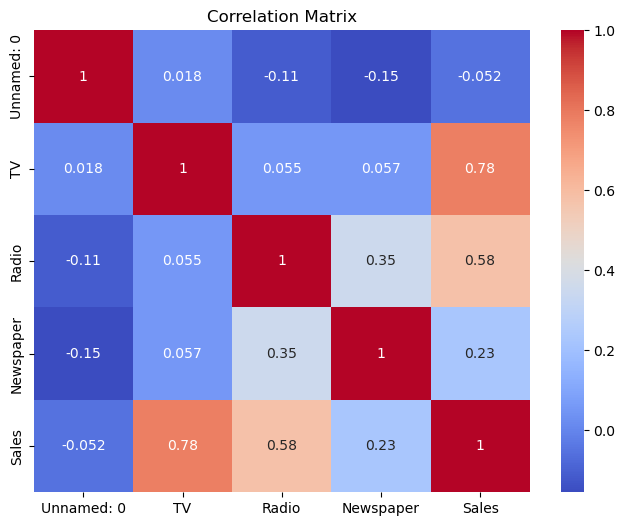

In [35]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

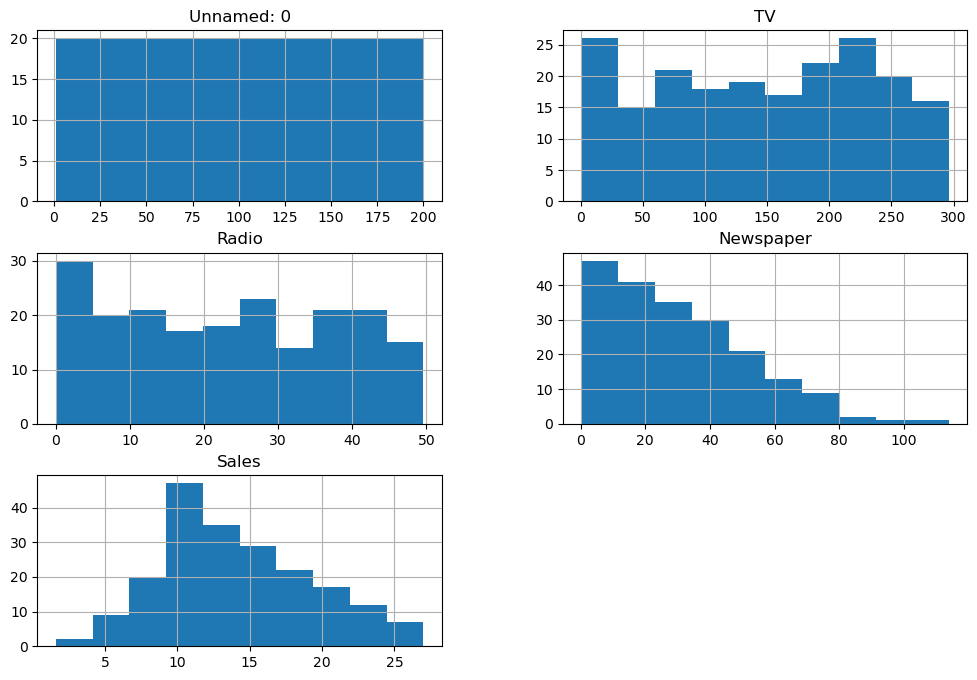

In [36]:
df.hist(figsize=(12,8))
plt.show()

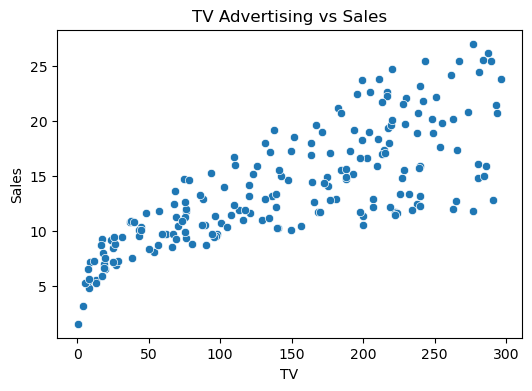

In [37]:
plt.figure(figsize=(6,4))
sns.scatterplot(x="TV", y="Sales", data=df)
plt.title("TV Advertising vs Sales")
plt.show()

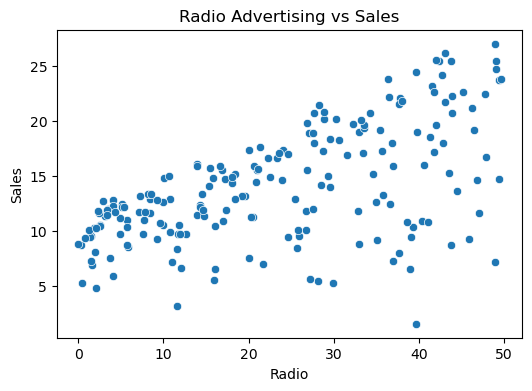

In [38]:
plt.figure(figsize=(6,4))
sns.scatterplot(x="Radio", y="Sales", data=df)
plt.title("Radio Advertising vs Sales")
plt.show()

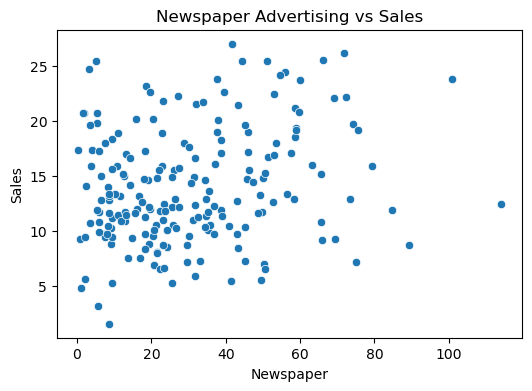

In [39]:
plt.figure(figsize=(6,4))
sns.scatterplot(x="Newspaper", y="Sales", data=df)
plt.title("Newspaper Advertising vs Sales")
plt.show()

In [40]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

In [41]:
X.head()

,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


In [42]:
y.head()

0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: Sales, dtype: float64

In [43]:
y.head()

0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: Sales, dtype: float64

In [44]:
from sklearn.model_selection import train_test_split

X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [45]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (160, 3)
X_test : (40, 3)
y_train: (160,)
y_test : (40,)


In [46]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)


LinearRegression()

In [47]:
y_pred = model.predict(X_test)

In [48]:
print(y_pred[:10])

[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326 13.10559172
 21.05719192  7.46101034 13.60634581 15.15506967]


In [49]:
comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

comparison.head(10)

,Actual Sales,Predicted Sales
0,16.9,16.408024
1,22.4,20.889882
2,21.4,21.553843
3,7.3,10.608503
4,24.7,22.112373
5,12.6,13.105592
6,22.3,21.057192
7,8.4,7.461010
8,11.5,13.606346
9,14.9,15.155070


In [50]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [51]:
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error (MAE):", mae)

Mean Absolute Error (MAE): 1.4607567168117606


In [52]:
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error (MSE):", mse)

Mean Squared Error (MSE): 3.1740973539761046


In [53]:
rmse = np.sqrt(mse)
print("Root Mean Squared Error (RMSE):", rmse)

Root Mean Squared Error (RMSE): 1.7815996615334502


In [54]:
r2 = r2_score(y_test, y_pred)
print("R² Score:", r2)

R² Score: 0.899438024100912


In [55]:
print("Model Performance")
print("-" * 30)
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

Model Performance
------------------------------
MAE : 1.4607567168117606
MSE : 3.1740973539761046
RMSE: 1.7815996615334502
R² Score: 0.899438024100912


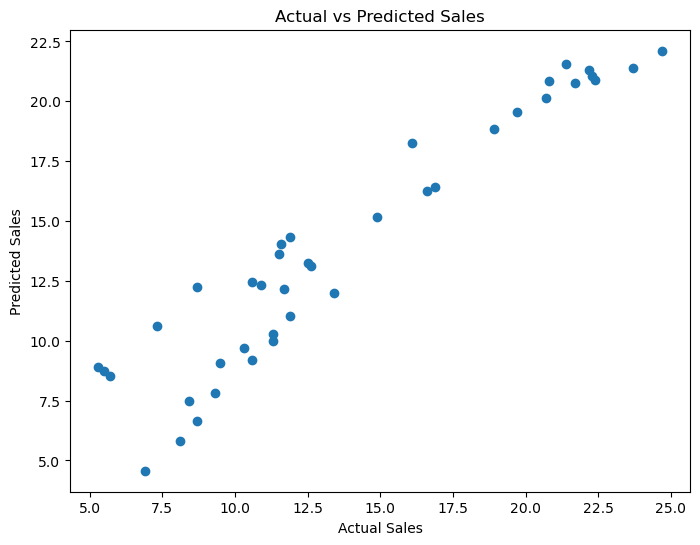

In [56]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

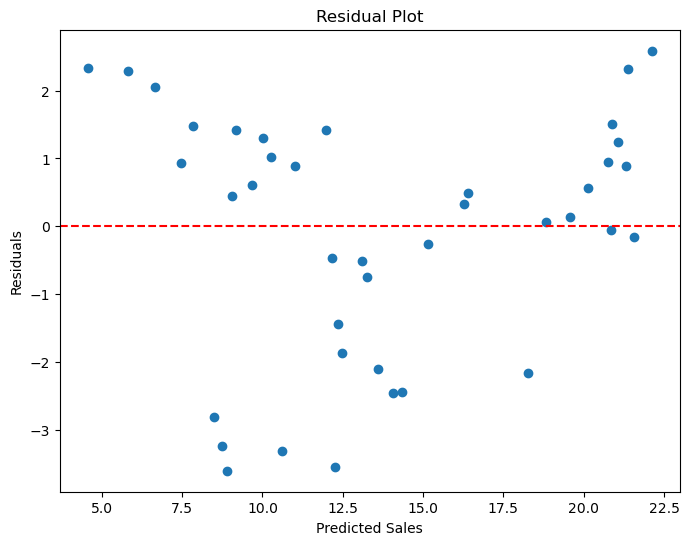

In [57]:
residuals = y_test - y_pred

plt.figure(figsize=(8,6))
plt.scatter(y_pred, residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [58]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

coefficients

,Feature,Coefficient
0,TV,0.044730
1,Radio,0.189195
2,Newspaper,0.002761


In [59]:
print("Intercept:", model.intercept_)

Intercept: 2.9790673381226274


In [60]:
new_data = pd.DataFrame({
    'TV': [230],
    'Radio': [37],
    'Newspaper': [69]
})

prediction = model.predict(new_data)

print("Predicted Sales:", prediction[0])

Predicted Sales: 20.45759025215365


In [61]:
new_data = pd.DataFrame({
    'TV': [150],
    'Radio': [25],
    'Newspaper': [20]
})

prediction = model.predict(new_data)

print("Predicted Sales:", prediction[0])

Predicted Sales: 14.473593601116836


In [62]:
import joblib

joblib.dump(model, "sales_prediction_model.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!


In [63]:
loaded_model = joblib.load("sales_prediction_model.pkl")

prediction = loaded_model.predict(new_data)

print(prediction)

[14.4735936]


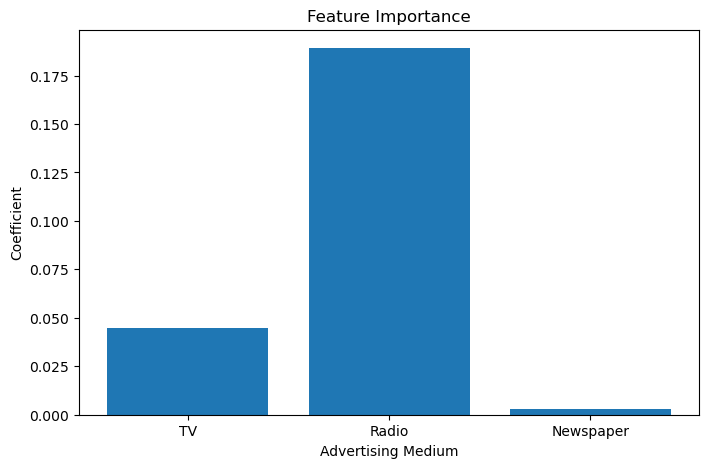

In [64]:
plt.figure(figsize=(8,5))

plt.bar(coefficients['Feature'], coefficients['Coefficient'])

plt.xlabel("Advertising Medium")
plt.ylabel("Coefficient")
plt.title("Feature Importance")

plt.show()

In [65]:
# Conclusion

- Successfully loaded and analyzed the advertising dataset.
- Performed data cleaning and exploratory data analysis (EDA).
- Built a Linear Regression model for sales prediction.
- Evaluated the model using MAE, MSE, RMSE, and R² Score.
- The model achieved a high R² score, indicating good predictive performance.
- TV and Radio advertising showed a stronger impact on sales compared to Newspaper advertising.
- The trained model can be used to estimate future sales based on advertising budgets.

SyntaxError: invalid character '²' (U+00B2) (265107008.py, line 6)

In [ ]:
# Business Insights

- TV advertising has the strongest influence on product sales.
- Radio advertising also contributes significantly to sales growth.
- Newspaper advertising has the least impact.
- Companies should allocate more budget to TV and Radio advertisements to maximize sales.
- The developed machine learning model can help businesses estimate future sales before launching advertising campaigns.

In [66]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [67]:
lr = LinearRegression()

dt = DecisionTreeRegressor(random_state=42)

rf = RandomForestRegressor(random_state=42)

In [68]:
lr.fit(X_train, y_train)

dt.fit(X_train, y_train)

rf.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [69]:
lr_pred = lr.predict(X_test)

dt_pred = dt.predict(X_test)

rf_pred = rf.predict(X_test)

In [70]:
from sklearn.metrics import r2_score, mean_absolute_error

In [71]:
result = pd.DataFrame({
    "Model": ["Linear Regression",
              "Decision Tree",
              "Random Forest"],

    "R2 Score":[
        r2_score(y_test, lr_pred),
        r2_score(y_test, dt_pred),
        r2_score(y_test, rf_pred)
    ],

    "MAE":[
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, dt_pred),
        mean_absolute_error(y_test, rf_pred)
    ]
})

result

,Model,R2 Score,MAE
0,Linear Regression,0.899438,1.460757
1,Decision Tree,0.931091,0.985000
2,Random Forest,0.981284,0.620100


In [72]:
result.sort_values(by="R2 Score", ascending=False)

,Model,R2 Score,MAE
2,Random Forest,0.981284,0.620100
1,Decision Tree,0.931091,0.985000
0,Linear Regression,0.899438,1.460757


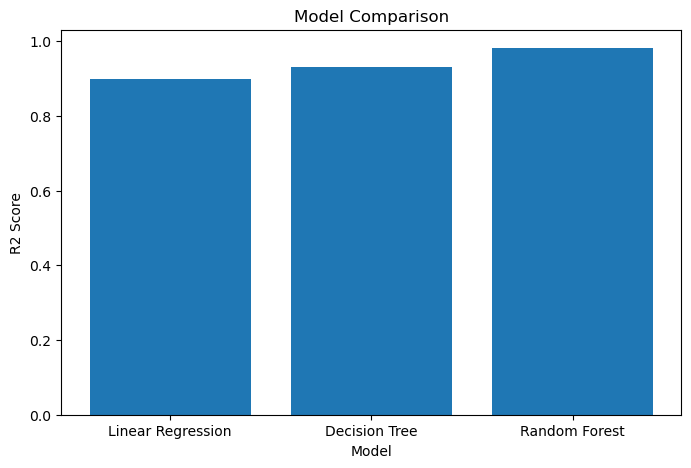

In [73]:
plt.figure(figsize=(8,5))

plt.bar(result["Model"], result["R2 Score"])

plt.xlabel("Model")

plt.ylabel("R2 Score")

plt.title("Model Comparison")

plt.show()

In [74]:
best_model = result.loc[result["R2 Score"].idxmax()]

print(best_model)

Model       Random Forest
R2 Score         0.981284
MAE                0.6201
Name: 2, dtype: object


In [75]:
import joblib

joblib.dump(rf, "best_sales_prediction_model.pkl")

['best_sales_prediction_model.pkl']

In [76]:
loaded_model = joblib.load("best_sales_prediction_model.pkl")

sample = pd.DataFrame({
    "TV":[150],
    "Radio":[30],
    "Newspaper":[20]
})

prediction = loaded_model.predict(sample)

print("Predicted Sales:", prediction[0])

Predicted Sales: 16.679999999999986


In [77]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    LinearRegression(),
    X,
    y,
    cv=5,
    scoring='r2'
)

print("Cross Validation Scores:", scores)
print("Average R² Score:", scores.mean())

Cross Validation Scores: [0.87865198 0.91763212 0.92933032 0.81443904 0.89547829]
Average R² Score: 0.8871063495438436


In [78]:
train_score = model.score(X_train, y_train)
test_score = model.score(X_test, y_test)

print("Training Accuracy :", train_score)
print("Testing Accuracy  :", test_score)

Training Accuracy : 0.8957008271017818
Testing Accuracy  : 0.899438024100912


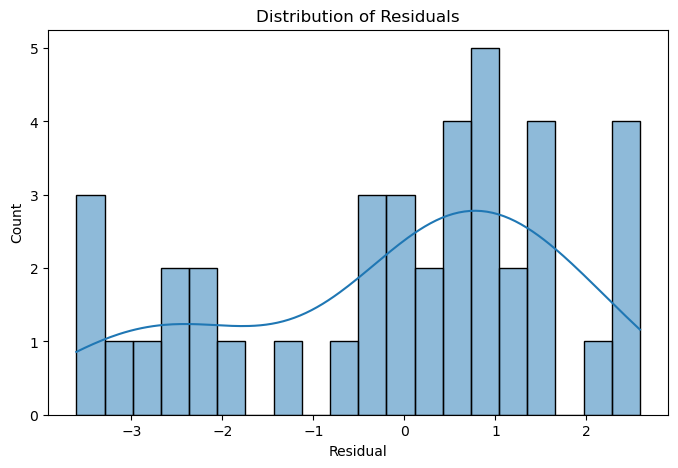

In [79]:
residuals = y_test - y_pred

plt.figure(figsize=(8,5))
sns.histplot(residuals, bins=20, kde=True)
plt.title("Distribution of Residuals")
plt.xlabel("Residual")
plt.show()

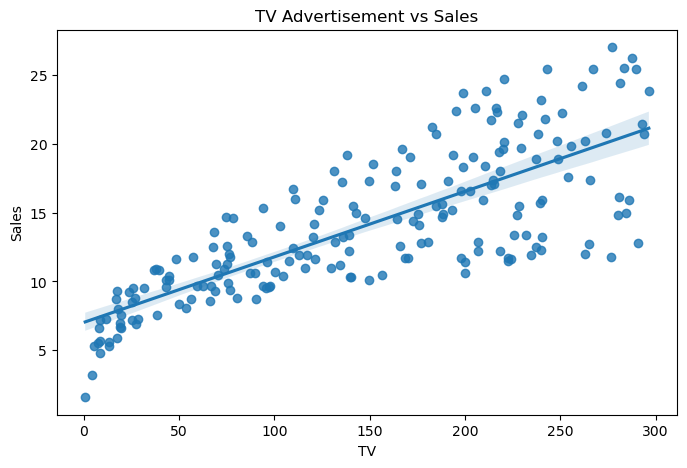

In [80]:
plt.figure(figsize=(8,5))
sns.regplot(x='TV', y='Sales', data=df)

plt.title("TV Advertisement vs Sales")
plt.show()

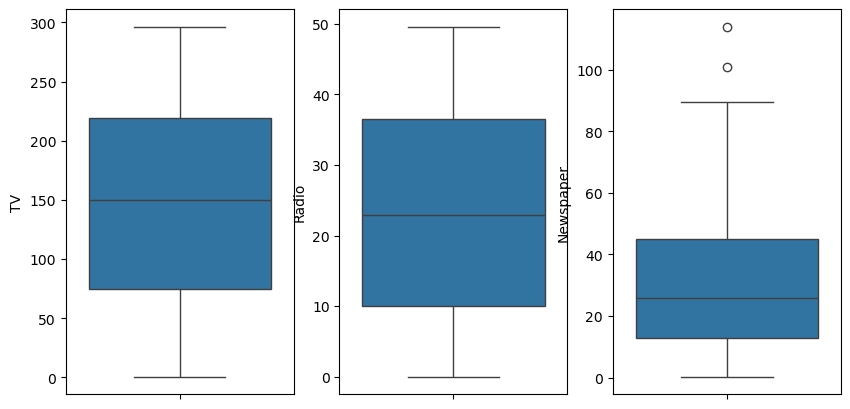

In [81]:
plt.figure(figsize=(10,5))

plt.subplot(1,3,1)
sns.boxplot(y=df["TV"])

plt.subplot(1,3,2)
sns.boxplot(y=df["Radio"])

plt.subplot(1,3,3)
sns.boxplot(y=df["Newspaper"])

plt.show()

In [82]:
correlation = df.corr()

print(correlation["Sales"].sort_values(ascending=False))

Sales         1.000000
TV            0.782224
Radio         0.576223
Newspaper     0.228299
Unnamed: 0   -0.051616
Name: Sales, dtype: float64


In [83]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": abs(model.coef_)
})

importance.sort_values(by="Importance", ascending=False)

,Feature,Importance
1,Radio,0.189195
0,TV,0.044730
2,Newspaper,0.002761


In [84]:
comparison.to_csv("Predicted_vs_Actual.csv", index=False)

print("CSV Saved Successfully!")

CSV Saved Successfully!


In [85]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 5, 10, 15],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200]},
             scoring='r2')

In [86]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}


In [87]:
best_rf = grid_search.best_estimator_

best_rf.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, random_state=42)

In [88]:
best_pred = best_rf.predict(X_test)

In [89]:
print("MAE :", mean_absolute_error(y_test, best_pred))
print("MSE :", mean_squared_error(y_test, best_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, best_pred)))
print("R2 Score:", r2_score(y_test, best_pred))

MAE : 0.6287125000000021
MSE : 0.5734048312500032
RMSE: 0.7572349907723515
R2 Score: 0.9818333477552758


In [90]:
import joblib

joblib.dump(best_rf, "optimized_sales_prediction_model.pkl")

print("Optimized Model Saved Successfully!")

Optimized Model Saved Successfully!


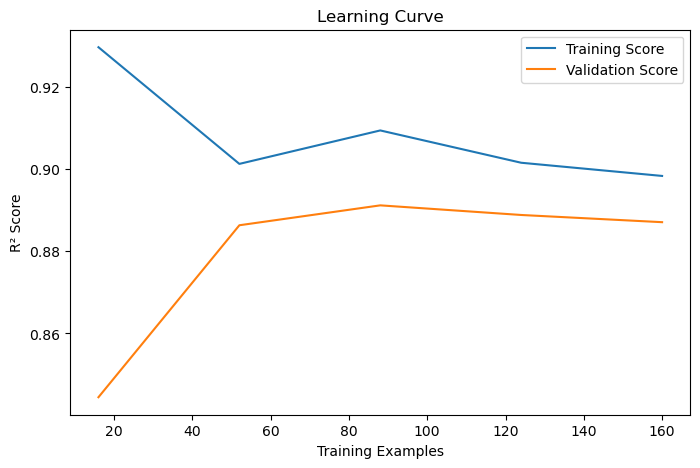

In [91]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, test_scores = learning_curve(
    model,
    X,
    y,
    cv=5,
    scoring='r2'
)

train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

plt.figure(figsize=(8,5))

plt.plot(train_sizes, train_mean, label="Training Score")
plt.plot(train_sizes, test_mean, label="Validation Score")

plt.xlabel("Training Examples")
plt.ylabel("R² Score")
plt.title("Learning Curve")
plt.legend()

plt.show()

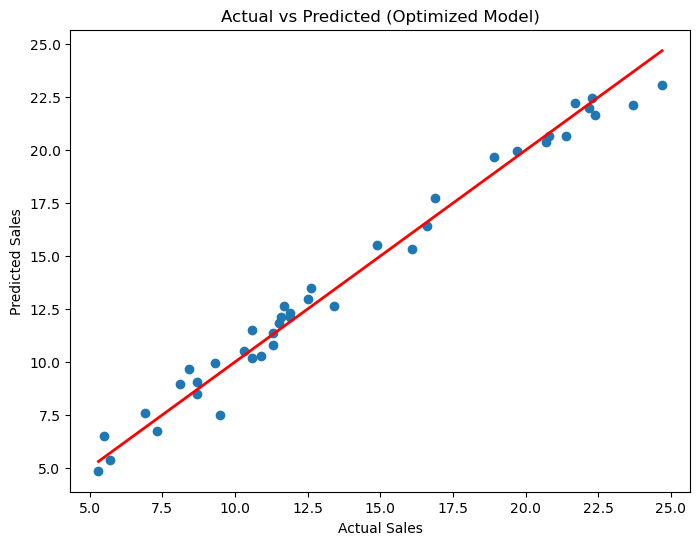

In [92]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, best_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted (Optimized Model)")

plt.show()

In [93]:
prediction_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": best_pred
})

prediction_df.to_csv("Sales_Predictions.csv", index=False)

prediction_df.head()

,Actual,Predicted
95,16.9,17.7615
15,22.4,21.6665
30,21.4,20.6595
158,7.3,6.7395
128,24.7,23.0960


In [94]:
#Actionable Insights for Business Marketing Strategies
1. Prioritize TV Advertising
The model shows that TV advertising has the strongest impact on sales.
Businesses should allocate a larger portion of their marketing budget to TV campaigns to maximize sales growth.
2. Increase Investment in Radio Advertising
Radio advertising also contributes positively to sales.
Combining TV and Radio campaigns can increase customer reach and improve overall campaign effectiveness.
3. Optimize Newspaper Advertising Budget
Newspaper advertising has the weakest influence on sales compared to TV and Radio.
Businesses should evaluate the return on investment (ROI) before increasing spending on newspaper advertisements.
4. Use Data-Driven Budget Allocation
Instead of distributing the advertising budget equally, businesses should allocate more resources to the channels that generate the highest sales impact.
The trained machine learning model can help estimate expected sales before launching campaigns.
5. Forecast Sales Before Marketing Campaigns
Marketing managers can use the prediction model to estimate future sales based on planned advertising budgets.
This enables better financial planning and reduces the risk of overspending.
6. Improve Return on Investment (ROI)
By focusing on high-performing advertising channels, businesses can reduce unnecessary marketing expenses and maximize profits.
7. Support Strategic Decision-Making
The model provides data-backed insights that help managers make informed decisions rather than relying on intuition.
Businesses can compare different advertising budget combinations and choose the most effective strategy.
8. Continuous Model Improvement
The prediction model should be retrained periodically using new advertising and sales data to maintain high prediction accuracy and adapt to changing market trends.

SyntaxError: invalid syntax (905799497.py, line 2)